# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [3]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [4]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[us]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   str           
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[us](1), int32(1), int64(7), str(1)
memory usage: 650.2 KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [5]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

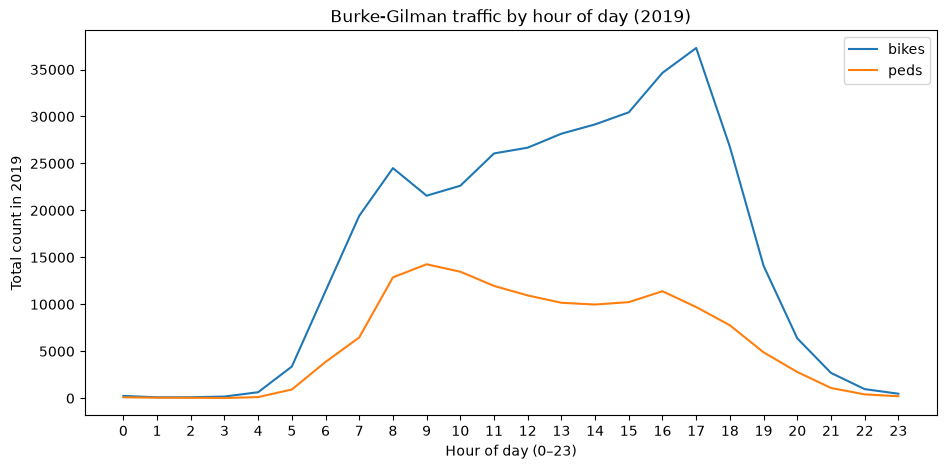

In [6]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

      bikes   peds  total
hour                     
0       245     98    343
1        99     58    157
2       103     44    147
3       179     24    203
4       640    120    760
5      3375    929   4304
6     11413   3862  15275
7     19422   6472  25894
8     24499  12870  37369
9     21565  14263  35828
10    22624  13471  36095
11    26064  11960  38024
12    26678  10943  37621
13    28166  10162  38328
14    29157   9975  39132
15    30443  10232  40675
16    34648  11393  46041
17    37291   9706  46997
18    26761   7767  34528
19    14101   4886  18987
20     6374   2793   9167
21     2696   1093   3789
22      969    407   1376
23      480    212    692

Busiest hour: 17:00 -> 46997 people (129 per day on average)
northbound bikes          12569
southbound bikes          24722
northbound pedestrians     4765
southbound pedestrians     4941
Name: 17, dtype: int64

Quietest hour: 2:00 -> 147 people

4–7pm share of all traffic: 25%


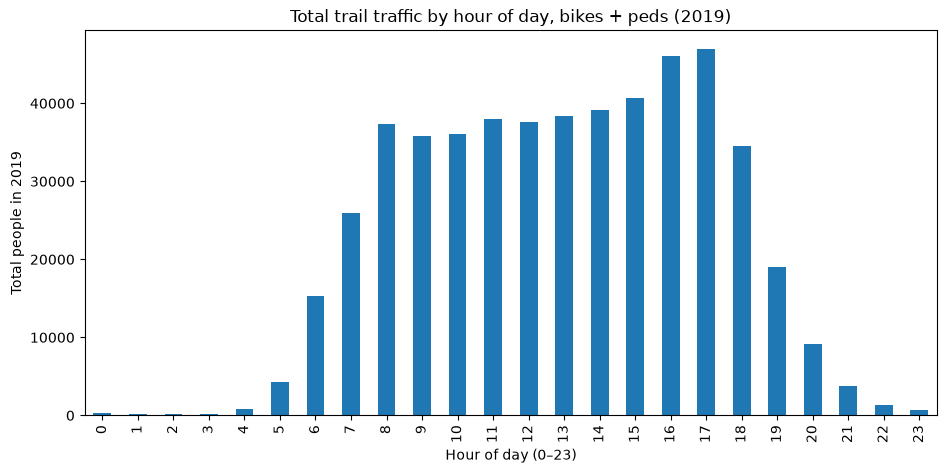

In [7]:
# Load the 2019 hourly totals by direction
hourly = pd.read_csv("bg_traffic_bike_ped_2019.csv")

# Convert "17:00:00" to the hour number 17
hourly["hour"] = pd.to_datetime(hourly["hour of the day"], format="%H:%M:%S").dt.hour
hourly = hourly.set_index("hour")

# Combine directions, then combine bikes and peds into one total
hourly["bikes"] = hourly["northbound bikes"] + hourly["southbound bikes"]
hourly["peds"]  = hourly["northbound pedestrians"] + hourly["southbound pedestrians"]
hourly["total"] = hourly["bikes"] + hourly["peds"]

# Busiest and quietest hours, with the raw counts behind each total
busiest = hourly["total"].idxmax()
quietest = hourly["total"].idxmin()
print(hourly[["bikes", "peds", "total"]])
print(f"\nBusiest hour: {busiest}:00 -> {hourly.loc[busiest, 'total']} people "
      f"({hourly.loc[busiest, 'total'] / 365:.0f} per day on average)")
print(hourly.loc[busiest, ["northbound bikes", "southbound bikes", "northbound pedestrians", "southbound pedestrians"]])
print(f"\nQuietest hour: {quietest}:00 -> {hourly.loc[quietest, 'total']} people")

# Share of all traffic in the 4–7pm stretch
evening_share = hourly.loc[16:18, "total"].sum() / hourly["total"].sum() * 100
print(f"\n4–7pm share of all traffic: {evening_share:.0f}%")

# Bar chart of total traffic by hour
hourly["total"].plot(kind="bar", figsize=(11, 5))
plt.title("Total trail traffic by hour of day, bikes + peds (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total people in 2019")
plt.show()


**Your Q1 answer:**

I used bg_traffic_bike_ped_2019.csv, which gives the total bikes and pedestrians counted in each direction at each hour of the day across 2019. I defined "busy" as all four columns added together, because walkers and cyclists both make the trail crowded. The busiest hour is 5pm, with 12,569 + 24,722 + 4,765 + 4,941 = 46,997 people (about 129 per day), and the 4–7pm stretch alone holds 25% of all traffic for the year. The quietest hour is 2am, with only 147 people all year. Most of the 5pm crowd is northbound and southbound bikes, so in Q2 I separated bikes from pedestrians to see whether they follow different schedules.

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

Bikes: 367992, Peds: 143740 -> 2.6 bikes per pedestrian

      bikes   peds  bike_pct  ped_pct
hour                                 
0       245     98       0.1      0.1
1        99     58       0.0      0.0
2       103     44       0.0      0.0
3       179     24       0.0      0.0
4       640    120       0.2      0.1
5      3375    929       0.9      0.6
6     11413   3862       3.1      2.7
7     19422   6472       5.3      4.5
8     24499  12870       6.7      9.0
9     21565  14263       5.9      9.9
10    22624  13471       6.1      9.4
11    26064  11960       7.1      8.3
12    26678  10943       7.2      7.6
13    28166  10162       7.7      7.1
14    29157   9975       7.9      6.9
15    30443  10232       8.3      7.1
16    34648  11393       9.4      7.9
17    37291   9706      10.1      6.8
18    26761   7767       7.3      5.4
19    14101   4886       3.8      3.4
20     6374   2793       1.7      1.9
21     2696   1093       0.7      0.8
22      969    407       0.3   

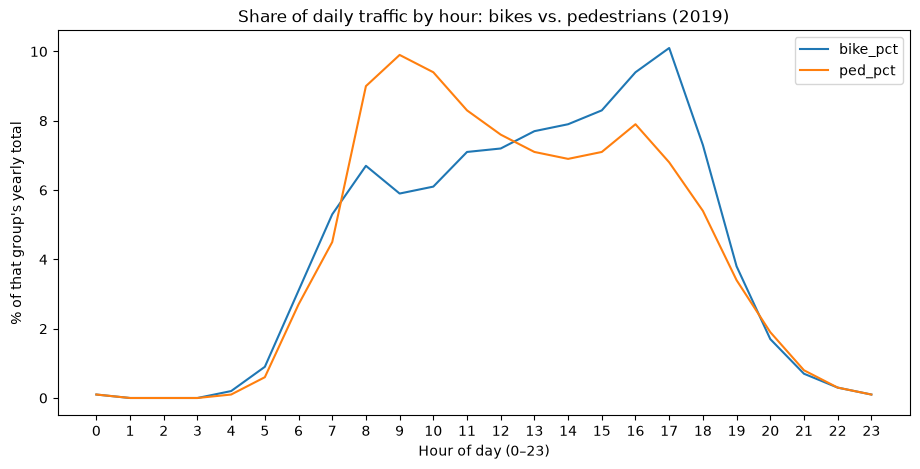

In [8]:
# Your code for Q2

# Percent of each group's yearly traffic in each hour, so bikes and peds can be compared despite different totals
hourly["bike_pct"] = (hourly["bikes"] / hourly["bikes"].sum() * 100).round(1)
hourly["ped_pct"]  = (hourly["peds"]  / hourly["peds"].sum()  * 100).round(1)

# Overall bike-to-ped ratio
print(f"Bikes: {hourly['bikes'].sum()}, Peds: {hourly['peds'].sum()} "
      f"-> {hourly['bikes'].sum() / hourly['peds'].sum():.1f} bikes per pedestrian\n")

# Peak hour for each group
print(hourly[["bikes", "peds", "bike_pct", "ped_pct"]])
for group, pct in [("bikes", "bike_pct"), ("peds", "ped_pct")]:
    peak = hourly[group].idxmax()
    print(f"{group} peak at {peak}:00 -> {hourly.loc[peak, group]} ({hourly.loc[peak, pct]}% of yearly {group})")

# Line chart comparing the daily shape of bike and ped traffic
hourly[["bike_pct", "ped_pct"]].plot(figsize=(11, 5))
plt.title("Share of daily traffic by hour: bikes vs. pedestrians (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("% of that group's yearly total")
plt.xticks(range(0, 24))
plt.show()


**Your Q2 answer:**

There were 2.6 bikes for every pedestrian in 2019 (367,992 vs. 143,740), so I compared what percent of each group's yearly traffic happens in each hour instead of raw counts. They follow different schedules. Bikes peak at 5pm (37,291 riders, 10.1% of all bikes), the same hour as the overall peak in Q1, while pedestrians peak at 9am (14,263 people, 9.9% of all pedestrians). In the chart, the pedestrian line slowly declines after 9am while the bike line keeps climbing until 5pm. This means the Q1 rush is driven by cyclists, which made me ask in Q3 whether those cyclists are commuting.

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

bikes: 11.9% in morning rush, 26.8% in evening rush
peds: 13.5% in morning rush, 20.1% in evening rush

Bikes 7–10am:
hour
7     19422
8     24499
9     21565
10    22624
Name: bikes, dtype: int64


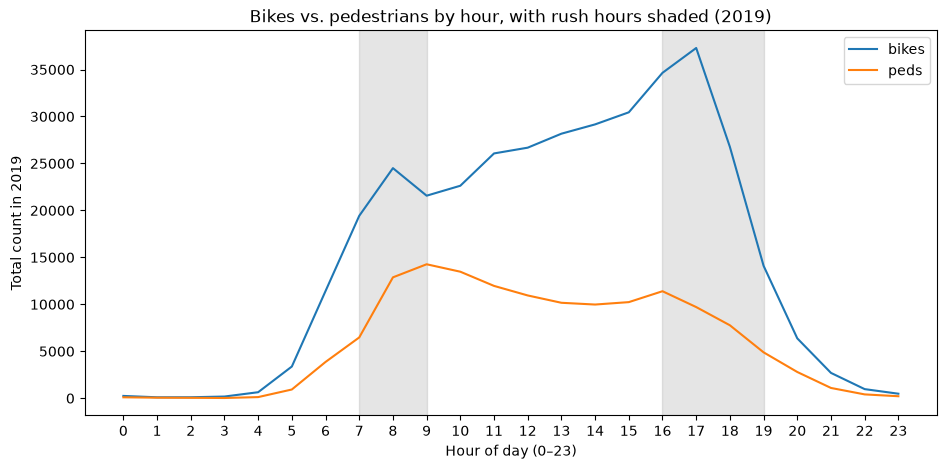

In [9]:
# Your code for Q3

# Rush-hour windows used to test for a commuting pattern
morning_rush = [7, 8]         # 7–9am
evening_rush = [16, 17, 18]   # 4–7pm

# Percent of each group's yearly traffic that falls in each rush window
for group in ["bikes", "peds"]:
    total = hourly[group].sum()
    am = hourly.loc[morning_rush, group].sum() / total * 100
    pm = hourly.loc[evening_rush, group].sum() / total * 100
    print(f"{group}: {am:.1f}% in morning rush, {pm:.1f}% in evening rush")

# Hourly bike counts around the morning rush, to check for a separate morning peak
print("\nBikes 7–10am:")
print(hourly.loc[7:10, "bikes"])

# Bikes and peds by hour, with rush hours shaded
hourly[["bikes", "peds"]].plot(figsize=(11, 5))
plt.axvspan(7, 9, color="gray", alpha=0.2)
plt.axvspan(16, 19, color="gray", alpha=0.2)
plt.title("Bikes vs. pedestrians by hour, with rush hours shaded (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()


**Your Q3 answer:**

If cyclists commute, I'd expect two peaks at rush hours: one in the morning and one in the late afternoon. The CSV only has totals by hour of day for the whole year, with no day of the week, so I couldn't compare weekdays to weekends and tested for rush-hour peaks instead. Bikes show both. They jump to 24,499 at 8am and then dip to 21,565 at 9am, a separate morning peak, and 26.8% of all bike traffic happens in the 4–7pm evening rush, which includes the 5pm peak from Q1 and Q2. Pedestrians actually have a slightly higher share in the morning rush (13.5% vs. 11.9% for bikes) because their peak is at 9am, but they have no evening jump (20.1%). This points to cyclists commuting, which I checked in Q4: if they are, they should ride one direction in the morning and the opposite direction in the evening.

**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

Morning (6–9am) Bikes: 37411 north, 17923 south -> 68% northbound
Morning (6–9am) Peds: 11684 north, 11520 south -> 50% northbound
Evening (4–7pm) Bikes: 35712 north, 62988 south -> 36% northbound
Evening (4–7pm) Peds: 14286 north, 14580 south -> 49% northbound


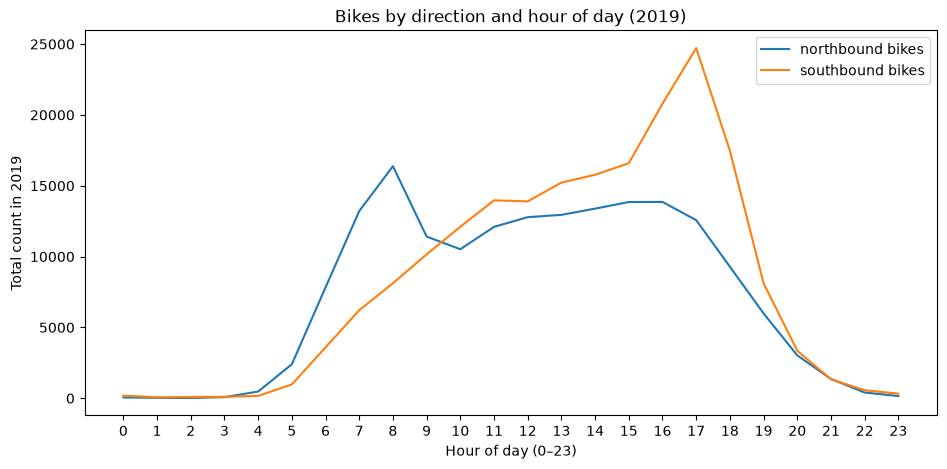

In [10]:
# Your code for Q4

# Morning and evening rush windows
morning = [6, 7, 8]       # 6–9am
evening = [16, 17, 18]    # 4–7pm

# Northbound vs. southbound counts and northbound share for each window
for label, hours in [("Morning (6–9am)", morning), ("Evening (4–7pm)", evening)]:
    for group, north, south in [("Bikes", "northbound bikes", "southbound bikes"),
                                ("Peds",  "northbound pedestrians", "southbound pedestrians")]:
        n = hourly.loc[hours, north].sum()
        s = hourly.loc[hours, south].sum()
        print(f"{label} {group}: {n} north, {s} south -> {n / (n + s) * 100:.0f}% northbound")

# Bike traffic by direction across the day
hourly[["northbound bikes", "southbound bikes"]].plot(figsize=(11, 5))
plt.title("Bikes by direction and hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()



**Your Q4 answer:**

Cyclists flip direction between the two rush hours. In the morning (6–9am), 68% of bikes head north (37,411 vs. 17,923), and in the evening (4–7pm), only 36% head north, so 64% head south (62,988 vs. 35,712). In the chart, the northbound line peaks in the morning and the southbound line peaks at 5pm. That southbound evening flow makes up most of the busiest hour found in Q1. Pedestrians stay about 50/50 at both times, which matches Q2 and Q3, where they looked recreational rather than commuting. Together, these results suggest many cyclists live south of the counter, ride north in the morning, and return home in the evening. The counter only records direction, not destination, so this is an inference rather than proof.

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

One limitation is that bg_traffic_bike_ped_2019.csv adds up the whole year by hour of day. That hides differences between weekdays and weekends and between summer and winter. A sunny July weekend and a rainy January Tuesday are blended into one number, which is why I couldn't test commuting directly in Q3. The counter also counts trips past one spot, not people. A commuter who rides north in the morning and south in the evening is counted twice, and someone who rides a short loop may pass more than once. Someone who trusted the totals uncritically might think 511,732 different people used the trail, or might assume the 5pm pattern holds every day of the year.

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.

## My use of AI

I used Claude (in VS Code) to help with Part 2 and Part 3.

**What Claude did:** wrote the Python code for Q1–Q4 and help cross check if the coding and my written answers made sense.

**What I directed and checked:**
- I told it to use only the data in my A1 folder (`bg_traffic_bike_ped_2019.csv`), not data pulled from the internet, so all numbers come from that file.
- I asked it to make the four answers connect to each other and to make sure every number in the written answers is printed by the code.
- I asked it to explain the code line by line and where each number came from to check that the code matched exactly with what I wanted it to do.

**Main prompts I used:**
- "please help me write the q1 code creating a table that shows total number of people (ped and bikes) for every house of the day.
- "for q4 please help me write code showing the peds and bikes direction (north bound or south bound) showing what percetage is the majority. We are looking at Morning (6-9am) and evenig (4-7pm).

